# Stage D — Multi-category retrieval

Resultados existentes: AP/mAP por categoria e curvas Precision–Recall no **teste**. Sem treino ou alteração de modelos.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Funciona com o notebook na pasta stageD ou com o Jupyter aberto na raiz do projeto.
candidates = [
    Path("aps_by_class.csv"),
    Path("stageD/aps_by_class.csv"),
    Path("results/part1/stageD/aps_by_class.csv"),
    Path("results/stageD/aps_by_class.csv"),
]
metrics_path = next((p.resolve() for p in candidates if p.is_file()), None)
if metrics_path is None:
    raise FileNotFoundError("Não foi encontrado stageD/aps_by_class.csv")

root = metrics_path.parent
out = root / "report_assets"
(out / "Images").mkdir(parents=True, exist_ok=True)
(out / "Tables").mkdir(parents=True, exist_ok=True)

ap_df = pd.read_csv(metrics_path)
print(f"Dados: {root}")

Dados: C:\IAVC\IAVC_proj_2\code\results\part1\stageD


## AP/mAP por categoria

In [2]:
# Uma única tabela: protocolo de validação + avaliação final no teste.
required = {"category", "split", "ap", "images", "positives"}
assert required.issubset(ap_df.columns), f"Colunas em falta: {required - set(ap_df.columns)}"

aps = ap_df.pivot(index="category", columns="split", values="ap")
counts = ap_df[ap_df["split"] == "test"].set_index("category")

rows = []
for cat in sorted(aps.index):
    trials = pd.read_csv(root / cat / "validation_trials.csv")
    selected_C = trials.loc[trials["validation_ap"].idxmax(), "C"]
    rows.append({
        "Category": cat.capitalize(),
        "Best C (val)": selected_C,
        "Train AP": aps.loc[cat, "train"],
        "Val AP": aps.loc[cat, "val"],
        "Test AP": aps.loc[cat, "test"],
        "Test positives (%)": 100 * counts.loc[cat, "positives"] / counts.loc[cat, "images"],
    })

summary = pd.DataFrame(rows)
mean_row = {col: float("nan") for col in summary.columns if col != "Category"}
mean_row.update({"Category": "mAP", **{
    col: summary[col].mean() for col in ["Train AP", "Val AP", "Test AP"]
}})
summary = pd.concat([summary, pd.DataFrame([mean_row])], ignore_index=True)

display(summary.style.format({
    "Best C (val)": "{:.1f}",
    "Train AP": "{:.3f}",
    "Val AP": "{:.3f}",
    "Test AP": "{:.3f}",
    "Test positives (%)": "{:.1f}",
}, na_rep="—").hide(axis="index"))
summary.to_csv(out / "Tables" / "stageD_ap_summary.csv", index=False)

Category,Best C (val),Train AP,Val AP,Test AP,Test positives (%)
Aeroplane,10.0,0.915,0.637,0.485,10.5
Car,1.0,0.791,0.693,0.680,23.8
Horse,10.0,0.969,0.835,0.612,12.1
Person,10.0,0.923,0.738,0.699,47.7
mAP,—,0.900,0.726,0.619,—


## Precision–Recall no teste

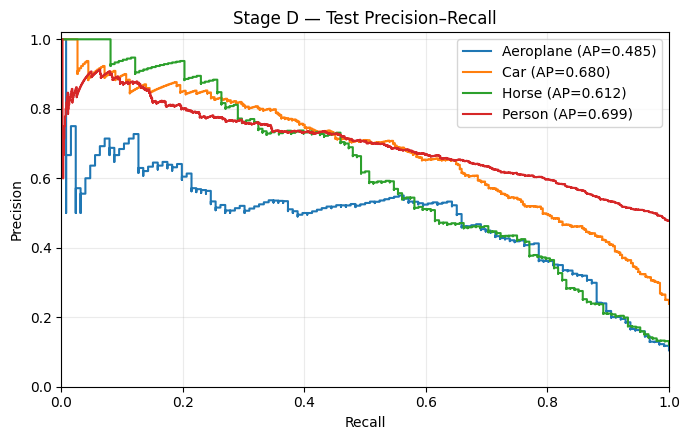

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for cat in sorted(aps.index):
    pr = pd.read_csv(root / cat / "test" / "precision_recall.csv")
    ap = aps.loc[cat, "test"]
    ax.step(pr["recall"], pr["precision"], where="post", label=f"{cat.capitalize()} (AP={ap:.3f})")

ax.set(xlabel="Recall", ylabel="Precision", title="Stage D — Test Precision–Recall")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(out / "Images" / "stageD_test_precision_recall.png", dpi=300, bbox_inches="tight")
plt.show()